# Regime Detection — HMM Training & Performance Analysis

Trains the from-scratch Gaussian HMM in [`src/regime_detector.py`](../src/regime_detector.py) on real BTC-USD trade data to classify market regimes, then wires the fitted model into the `Simulator` so the market maker switches its risk parameters (`gamma`, `kappa`) based on the *currently detected* regime rather than a fixed value. Performance is compared against the static-parameter baseline from `04_performance_analysis.ipynb`.

**Note on `regime_detector.py`:** while building this notebook, the original `forward`/`backward` implementation turned out to underflow to exactly `0.0` on any sequence longer than ~150 steps (unscaled probabilities compounding every timestep), which silently breaks both `fit()` and `predict_regime()` on realistically long trade data. It now uses the standard Rabiner scaled forward-backward algorithm, plus a small covariance ridge and a vectorized emission step (scipy's `pdf` evaluated once per state across the whole sequence instead of once per timestep), which also cut training time by roughly two orders of magnitude.

## 1. Data

Same BTC-USD trade feed used in `04_performance_analysis.ipynb` and `05_bayesian_optimization.ipynb`.

In [1]:
import sys
sys.path.append('..')
from src.order_book import OrderBook, Side
from src.market_maker import MarketMaker
from src.simulator import Simulator
from src.regime_detector import HMM

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
def get_btc_trades_extended(n_batches=20):
    url = "https://api.exchange.coinbase.com/products/BTC-USD/trades"
    all_trades = []

    params = {"limit": 1000}
    for _ in range(n_batches):
        response = requests.get(url, params=params)
        batch = response.json()
        if not batch:
            break
        all_trades.extend(batch)
        oldest_id = min(t["trade_id"] for t in batch)
        params = {"limit": 1000, "after": oldest_id}

    df = pd.DataFrame(all_trades)
    df["price"] = pd.to_numeric(df["price"])
    df["size"] = pd.to_numeric(df["size"])
    df["time"] = pd.to_datetime(df["time"])
    df = df.drop_duplicates(subset="trade_id")
    df = df.sort_values("time").reset_index(drop=True)
    df = df.set_index("time")
    return df

In [3]:
trades = get_btc_trades_extended()
print(f"Got {len(trades)} trades")

Got 20000 trades


## 2. Feature Engineering

Three features per observation, matching exactly what `Simulator.current_observation` computes live during a run so the fitted HMM sees the same units at train time and at inference time inside the simulation loop:

- **log return** of the trade price
- **dynamic sigma**: rolling std of log returns (realised volatility proxy)
- **OFI**: rolling order flow imbalance (buy volume vs. sell volume)

Tick-level features are noisy and the from-scratch Baum–Welch EM in `regime_detector.py` is a pure-Python per-timestep loop, so fitting directly on every one of several thousand ticks is both noisy and slow. Observations are aggregated into fixed-size trade bars (mean of every `bar_size` ticks) purely for *training* — the live simulation still runs tick-by-tick.

In [4]:
def build_observations(df, window=20, ofi_window=50):
    log_returns = np.log(df['price'] / df['price'].shift(1))
    dyn_sigma = log_returns.rolling(window).std()
    buy_vol = df['size'].where(df['side'] == 'buy', 0.0).rolling(ofi_window).sum()
    sell_vol = df['size'].where(df['side'] == 'sell', 0.0).rolling(ofi_window).sum()
    ofi = (buy_vol - sell_vol) / (buy_vol + sell_vol).replace(0, np.nan)
    obs = pd.DataFrame({'log_return': log_returns, 'dyn_sigma': dyn_sigma, 'ofi': ofi}).fillna(0.0)
    return obs.values

def make_bars(obs, bar_size=10):
    T = len(obs) // bar_size
    return obs[:T * bar_size].reshape(T, bar_size, obs.shape[1]).mean(axis=1)

tick_obs = build_observations(trades)
bar_obs = make_bars(tick_obs, bar_size=10)
print(f"{len(tick_obs)} tick-level observations -> {len(bar_obs)} training bars")

20000 tick-level observations -> 2000 training bars


## 3. Fit the HMM

`n_states=3` to represent calm/mean-reverting, trending, and high-volatility conditions. EM is non-convex and sensitive to its random initial `mu`, so several random restarts are run and the one with the highest converged log-likelihood is kept.

In [5]:
from sklearn.preprocessing import StandardScaler

# Fit the scaler on tick-level observations, not the bar-aggregated ones used
# for training below. Simulator.current_observation feeds single-tick features
# into this same scaler live; averaging 10 ticks into a bar shrinks variance by
# roughly sqrt(10), so a scaler fit on bars assigns inflated z-scores to every
# live tick, making it look like a permanent outlier to the fitted model. Since
# StandardScaler is an affine transform, scaling before or after bar-averaging
# gives identical bars as long as the mean/std come from the tick population --
# so this keeps the smoothing benefit of bar training without the scale mismatch.
scaler = StandardScaler().fit(tick_obs)
bar_obs_scaled = scaler.transform(bar_obs)

def fit_best_hmm(obs, n_states=3, n_restarts=5, n_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    best_hmm, best_ll = None, -np.inf

    for i in range(n_restarts):
        np.random.seed(int(rng.integers(0, 1_000_000)))
        hmm = HMM(n_states=n_states, n_feats=obs.shape[1])
        hmm.fit(obs, n_iter=n_iter)
        alpha, c = hmm.forward_scaled(obs)
        ll = np.sum(np.log(c))
        if np.isfinite(ll) and ll > best_ll:
            best_ll = ll
            best_hmm = hmm

    return best_hmm, best_ll

hmm, best_ll = fit_best_hmm(bar_obs_scaled, n_states=3, n_restarts=5, n_iter=100)
print(f"Best log-likelihood: {best_ll:.2f}")

Converged at iteration 50
Converged at iteration 48
Converged at iteration 45
Converged at iteration 71
Best log-likelihood: 153.31


## 4. Interpreting the Learned Regimes

In [6]:
regime_table = pd.DataFrame(hmm.mu, columns=['log_return', 'dyn_sigma', 'ofi'])
regime_table['vol'] = [np.sqrt(np.trace(s)) for s in hmm.sigma]
print("Learned state means:")
print(regime_table)
print("\nTransition matrix A:")
print(pd.DataFrame(hmm.A))

Learned state means:
   log_return  dyn_sigma       ofi       vol
0   -0.066715   1.348194  0.531954  1.766625
1    0.045143  -0.181077 -0.158390  0.949806
2    0.001053  -0.392729 -0.110789  1.045425

Transition matrix A:
          0         1         2
0  0.690459  0.037333  0.272209
1  0.097231  0.463436  0.439333
2  0.061994  0.259592  0.678414


State -> label mapping (by realised volatility): {0: 'volatile', 1: 'trending', 2: 'mean_reverting'}


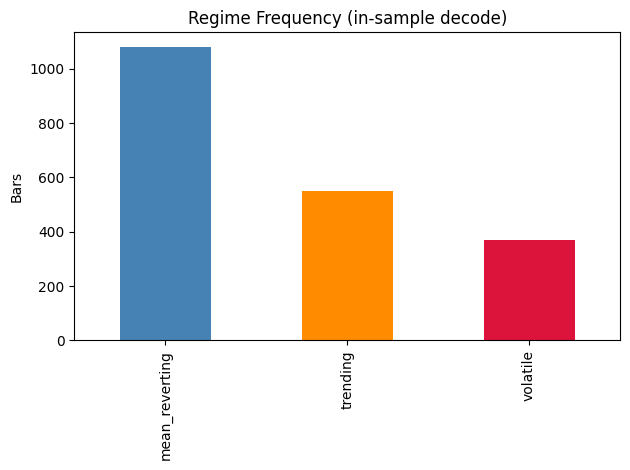

In [7]:
alpha, c = hmm.forward_scaled(bar_obs_scaled)
beta = hmm.backward_scaled(bar_obs_scaled, c)
gamma_post = hmm.compute_gamma(alpha, beta)
state_sequence = gamma_post.argmax(axis=1)

# Label states by realised volatility: calmest -> most volatile
vol_rank = regime_table['dyn_sigma'].rank().astype(int) - 1
labels = {0: 'mean_reverting', 1: 'trending', 2: 'volatile'}
state_to_label = {state: labels[rank] for state, rank in vol_rank.items()}
print("State -> label mapping (by realised volatility):", state_to_label)

counts = pd.Series(state_sequence).map(state_to_label).value_counts()
counts.plot(kind='bar', color=['steelblue', 'darkorange', 'crimson'])
plt.ylabel('Bars')
plt.title('Regime Frequency (in-sample decode)')
plt.tight_layout()
plt.show()

## 5. Regime-Conditional Market Making

`Simulator` already supports an `hmm` + `regime_params` pair: on every step, once the sliding observation buffer fills the `window`, it calls `hmm.predict_regime(...)` and applies `regime_params[regime]` to `mm.gamma`/`mm.kappa` (see `Simulator._apply_regime`). `regime_params` is keyed by the *raw integer state* `predict_regime` returns, so the label mapping above is used to assign calibrated parameters to each state: the `mean_reverting` baseline uses `04_performance_analysis.ipynb`'s tuned optimum (`gamma=0.5`, `kappa=11.0`), while `trending`/`volatile` states get progressively wider spreads (lower `kappa`) and heavier inventory aversion (higher `gamma`) — consistent with that notebook's finding that a market maker should defend against directional exposure in trending regimes.

In [8]:
label_to_params = {
    'mean_reverting': {'gamma': 0.5, 'kappa': 11.0},
    'trending':       {'gamma': 0.8, 'kappa': 6.0},
    'volatile':       {'gamma': 1.2, 'kappa': 3.0},
}
regime_params = {state: label_to_params[label] for state, label in state_to_label.items()}
regime_params

{0: {'gamma': 1.2, 'kappa': 3.0},
 1: {'gamma': 0.8, 'kappa': 6.0},
 2: {'gamma': 0.5, 'kappa': 11.0}}

In [9]:
def run_backtest(trades=trades, hmm=None, regime_params=None, scaler=None, gamma=0.5, kappa=11.0):
    book = OrderBook()
    mm = MarketMaker(starting_wealth=100000, order_book=book, gamma=gamma, kappa=kappa)
    sim = Simulator(mm, book, trades, window=20, hmm=hmm, regime_params=regime_params, scaler=scaler)
    mm.start_session()
    sim.run(pause_threshold=0.75)
    return sim.get_results()

baseline_results = run_backtest(gamma=0.5, kappa=11.0)
regime_results = run_backtest(hmm=hmm, regime_params=regime_params, scaler=scaler)
print("Both runs complete")

Both runs complete


## 6. Performance Comparison

In [10]:
def summarize(results, label):
    returns = results['PnL'].diff().dropna()
    rolling_max = results['PnL'].cummax()
    drawdown = rolling_max - results['PnL']
    win_rate = (returns > 0).sum() / len(returns)
    avg_win = returns[returns > 0].mean()
    avg_loss = returns[returns < 0].mean()
    return {
        'label': label,
        'Sharpe': returns.mean() / returns.std(),  # raw per-trade Sharpe -- matches 05_bayesian_optimization.ipynb's convention (no annualization factor), which is what's compared against in Section 7.3
        'Max Drawdown': drawdown.max(),
        'Win Rate': win_rate,
        'Profit Factor': abs(avg_win / avg_loss),
        'Final PnL': results['PnL'].iloc[-1],
        'Final Position': results['Position'].iloc[-1],
    }

summary = pd.DataFrame([
    summarize(baseline_results, 'Static (baseline)'),
    summarize(regime_results, 'HMM regime-conditional'),
]).set_index('label')
summary

,Sharpe,Max Drawdown,Win Rate,Profit Factor,Final PnL,Final Position
label,,,,,,
Static (baseline),-0.007870,62.345859,0.429821,0.872757,-12.987473,0.579543
HMM regime-conditional,-0.003883,33.449725,0.437672,0.834705,-4.077917,0.336440


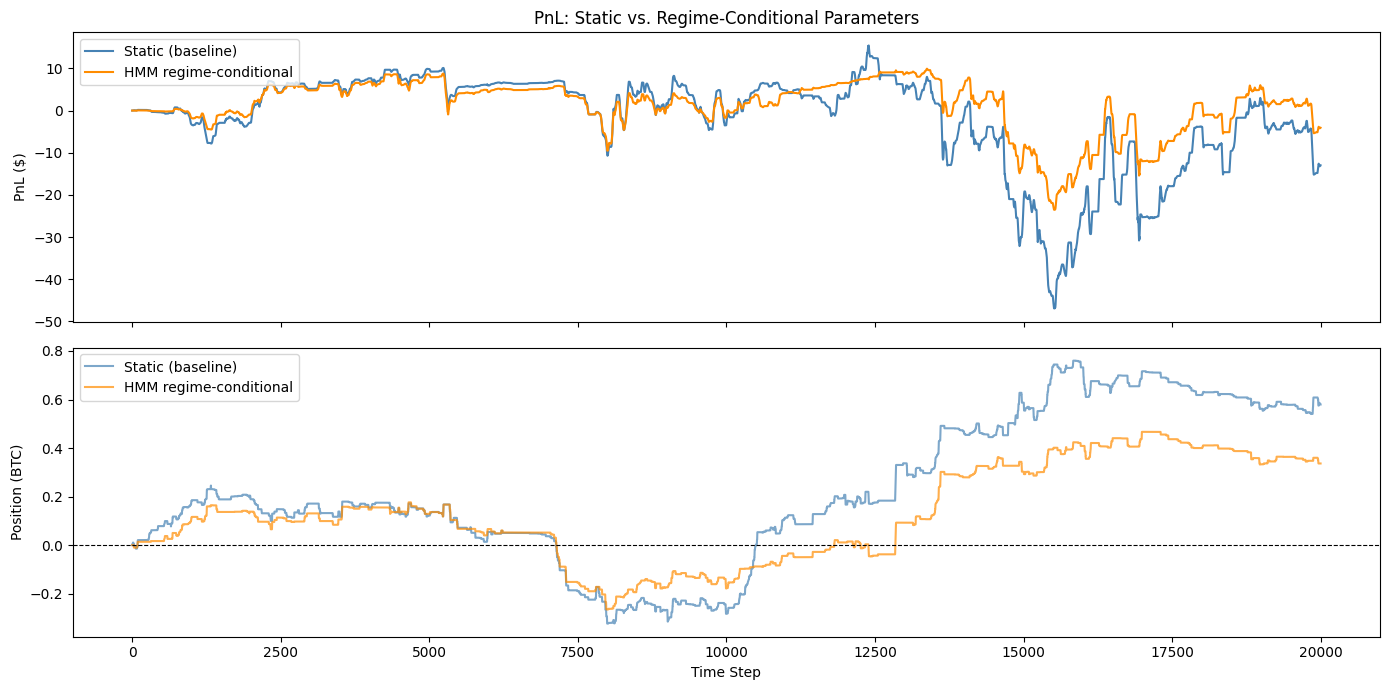

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(baseline_results.index, baseline_results['PnL'], label='Static (baseline)', color='steelblue')
ax1.plot(regime_results.index, regime_results['PnL'], label='HMM regime-conditional', color='darkorange')
ax1.set_ylabel('PnL ($)')
ax1.legend(loc='upper left')
ax1.set_title('PnL: Static vs. Regime-Conditional Parameters')

ax2.plot(baseline_results.index, baseline_results['Position'], label='Static (baseline)', color='steelblue', alpha=0.7)
ax2.plot(regime_results.index, regime_results['Position'], label='HMM regime-conditional', color='darkorange', alpha=0.7)
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.set_ylabel('Position (BTC)')
ax2.set_xlabel('Time Step')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

## 7. Out-of-Sample Validation vs. Bayesian Optimization

Everything above is trained and evaluated on the same trade window - a result that looks good in-sample can still be overfit noise. This section tests the HMM the way `05_bayesian_optimization.ipynb` tested its Optuna-tuned parameters: fit strictly on a training fold, then run the fitted model, untouched, on a later held-out fold.

**A caveat worth stating plainly:** Coinbase's trades endpoint only serves recent trades, not a specific historical window, so there's no way to replay `05`'s exact training/validation period here. The numbers below come from a fresh live pull taken while running this notebook. The comparison with `05` is therefore a *same-methodology, different-period* comparison - a fair test of whether the same validation approach reaches a similar conclusion, not a literal apples-to-apples replay. The Bayesian-optimization figures themselves are the ones already committed in that notebook's output, cited rather than re-run (re-running its 100-trial-per-fold search here would take the same 60-90 minutes `05` already spent, against yet another different live window).

### 7.1 Single Train/Validation Split

Mirrors `05`'s initial methodology: pull 10,000 trades, train on the first 7,000, validate on the untouched remaining 3,000. The scaler and HMM are fit *only* on the training fold; `oos_val` never influences either.

In [12]:
oos_trades = get_btc_trades_extended(n_batches=20)
oos_train = oos_trades.iloc[:7000]
oos_val = oos_trades.iloc[7000:]

print(f"OOS train: {len(oos_train)} trades, price change ${oos_train['price'].iloc[-1] - oos_train['price'].iloc[0]:.2f}")
print(f"OOS val:   {len(oos_val)} trades, price change ${oos_val['price'].iloc[-1] - oos_val['price'].iloc[0]:.2f}")

OOS train: 7000 trades, price change $64.85
OOS val:   13000 trades, price change $-74.07


In [13]:
oos_train_tick_obs = build_observations(oos_train)
oos_train_bar_obs = make_bars(oos_train_tick_obs, bar_size=10)

oos_scaler = StandardScaler().fit(oos_train_tick_obs)
oos_train_bar_obs_scaled = oos_scaler.transform(oos_train_bar_obs)

oos_hmm, oos_ll = fit_best_hmm(oos_train_bar_obs_scaled, n_states=3, n_restarts=5, n_iter=100)

oos_regime_table = pd.DataFrame(oos_hmm.mu, columns=['log_return', 'dyn_sigma', 'ofi'])
oos_vol_rank = oos_regime_table['dyn_sigma'].rank().astype(int) - 1
oos_state_to_label = {state: labels[rank] for state, rank in oos_vol_rank.items()}
oos_regime_params = {state: label_to_params[label] for state, label in oos_state_to_label.items()}

print(f"Train-fold log-likelihood: {oos_ll:.2f}")
print("Train-fold state -> label mapping:", oos_state_to_label)

Converged at iteration 52
Converged at iteration 36
Train-fold log-likelihood: 144.31
Train-fold state -> label mapping: {0: 'volatile', 1: 'trending', 2: 'mean_reverting'}


In [14]:
oos_static_results = run_backtest(trades=oos_val, gamma=0.5, kappa=11.0)
oos_regime_results = run_backtest(trades=oos_val, hmm=oos_hmm, regime_params=oos_regime_params, scaler=oos_scaler)

oos_summary = pd.DataFrame([
    summarize(oos_static_results, 'Static (this notebook)'),
    summarize(oos_regime_results, 'HMM regime-conditional (this notebook)'),
]).set_index('label')

# Committed results from 05_bayesian_optimization.ipynb Section 2 (cells 11/13) -- a
# different live trade window, same train-then-hold-out methodology. Sharpe only; that
# notebook didn't report drawdown/win-rate/PnL for this particular split.
bayesian_oos_reference = pd.DataFrame([
    {'label': 'Bayesian-optimized (05, single split)', 'Sharpe': -0.1866},
    {'label': 'Static baseline (05, single split)', 'Sharpe': -0.1120},
]).set_index('label')

print(oos_summary)
print()
print(bayesian_oos_reference)

                                          Sharpe  Max Drawdown  Win Rate  \
label                                                                      
Static (this notebook)                 -0.014454     74.605392  0.425110   
HMM regime-conditional (this notebook) -0.009518     41.087337  0.431572   

                                        Profit Factor  Final PnL  \
label                                                              
Static (this notebook)                       0.902144 -19.871754   
HMM regime-conditional (this notebook)       0.859048  -8.086157   

                                        Final Position  
label                                                   
Static (this notebook)                        0.577389  
HMM regime-conditional (this notebook)        0.335828  

                                       Sharpe
label                                        
Bayesian-optimized (05, single split) -0.1866
Static baseline (05, single split)    -0.1120


### 7.2 Walk-Forward Validation for HMM Training

A single split is vulnerable to whatever regime happens to land in the validation window - `05` ran into exactly that (bullish train, bearish validation) and only trusted its result once a 4-fold walk-forward confirmed it. The same fold structure is used here for comparability: `train_size=12000`, `val_size=2000`, `step_size=2000`, stepping forward over a ~20,000-trade pull.

**What's actually retrained each fold** is narrower than what `05` retrains: this loop re-fits the scaler and the HMM classifier from scratch on each training fold, then applies the fixed, hand-calibrated `label_to_params` mapping from Section 5 to whatever regimes that fold's HMM discovers. `05`'s walk-forward re-runs a full 100-trial Optuna search per fold, jointly re-optimizing `gamma`, `kappa`, `alpha`, `beta`, the OFI threshold and the window length. This loop does not re-optimize `label_to_params` itself -- doing that jointly, per fold, is exactly the "fold `regime_params` into Bayesian optimization" idea `05`'s own conclusion flags as future work, and is noted again at the end of this section.

In [15]:
def walk_forward_hmm_validation(all_trades, train_size=12000, val_size=2000, step_size=2000):
    folds = []
    start = 0
    fold_num = 1

    while start + train_size + val_size <= len(all_trades):
        train = all_trades.iloc[start:start + train_size]
        val = all_trades.iloc[start + train_size:start + train_size + val_size]

        train_tick_obs = build_observations(train)
        train_bar_obs = make_bars(train_tick_obs, bar_size=10)
        fold_scaler = StandardScaler().fit(train_tick_obs)
        train_bar_obs_scaled = fold_scaler.transform(train_bar_obs)

        fold_hmm, fold_ll = fit_best_hmm(train_bar_obs_scaled, n_states=3, n_restarts=5, n_iter=100)

        fold_regime_table = pd.DataFrame(fold_hmm.mu, columns=['log_return', 'dyn_sigma', 'ofi'])
        fold_vol_rank = fold_regime_table['dyn_sigma'].rank().astype(int) - 1
        fold_state_to_label = {state: labels[rank] for state, rank in fold_vol_rank.items()}
        fold_regime_params = {state: label_to_params[label] for state, label in fold_state_to_label.items()}

        static_val = run_backtest(trades=val, gamma=0.5, kappa=11.0)
        regime_val = run_backtest(trades=val, hmm=fold_hmm, regime_params=fold_regime_params, scaler=fold_scaler)

        static_summary = summarize(static_val, 'static')
        regime_summary = summarize(regime_val, 'regime')

        folds.append({
            'fold': fold_num,
            'train_price_change': train['price'].iloc[-1] - train['price'].iloc[0],
            'val_price_change': val['price'].iloc[-1] - val['price'].iloc[0],
            'train_ll': fold_ll,
            'state_to_label': fold_state_to_label,
            'static_sharpe': static_summary['Sharpe'],
            'static_drawdown': static_summary['Max Drawdown'],
            'static_pnl': static_summary['Final PnL'],
            'regime_sharpe': regime_summary['Sharpe'],
            'regime_drawdown': regime_summary['Max Drawdown'],
            'regime_pnl': regime_summary['Final PnL'],
        })

        print(f"Fold {fold_num}: train ${train['price'].iloc[-1]-train['price'].iloc[0]:.2f}, "
              f"val ${val['price'].iloc[-1]-val['price'].iloc[0]:.2f}  |  "
              f"static Sharpe={static_summary['Sharpe']:.4f}  regime Sharpe={regime_summary['Sharpe']:.4f}")

        start += step_size
        fold_num += 1

    return folds

*(Expect a few minutes' runtime -- 4 folds, each refitting the HMM with 5 restarts and running two full backtests.)*

In [16]:
walk_forward_trades = get_btc_trades_extended(n_batches=20)
wf_folds = walk_forward_hmm_validation(walk_forward_trades)

Converged at iteration 89
Converged at iteration 60
Converged at iteration 97
Converged at iteration 54
Fold 1: train $93.38, val $-66.23  |  static Sharpe=-0.0710  regime Sharpe=-0.0710
Converged at iteration 65
Converged at iteration 51
Converged at iteration 60
Converged at iteration 55
Converged at iteration 73
Fold 2: train $5.64, val $-40.78  |  static Sharpe=0.0777  regime Sharpe=0.0828
Converged at iteration 39
Converged at iteration 44
Converged at iteration 52
Converged at iteration 85
Converged at iteration 42
Fold 3: train $-33.76, val $6.34  |  static Sharpe=0.1828  regime Sharpe=0.0368
Converged at iteration 54
Converged at iteration 50
Converged at iteration 72
Converged at iteration 46
Converged at iteration 41
Fold 4: train $-26.00, val $-4.19  |  static Sharpe=0.1890  regime Sharpe=0.1876


In [17]:
wf_df = pd.DataFrame(wf_folds)
print(wf_df[['fold', 'train_price_change', 'val_price_change', 'static_sharpe', 'regime_sharpe', 'static_drawdown', 'regime_drawdown']].to_string())

print(f"\nMean static Sharpe:  {wf_df['static_sharpe'].mean():.4f}  (std {wf_df['static_sharpe'].std():.4f})")
print(f"Mean regime Sharpe:  {wf_df['regime_sharpe'].mean():.4f}  (std {wf_df['regime_sharpe'].std():.4f})")

   fold  train_price_change  val_price_change  static_sharpe  regime_sharpe  static_drawdown  regime_drawdown
0     1               93.38            -66.23      -0.070959      -0.070959        16.022163        16.022163
1     2                5.64            -40.78       0.077746       0.082789        10.886773         4.958932
2     3              -33.76              6.34       0.182792       0.036829         0.610023         1.391704
3     4              -26.00             -4.19       0.188995       0.187557         0.102953         0.121270

Mean static Sharpe:  0.0946  (std 0.1216)
Mean regime Sharpe:  0.0591  (std 0.1072)


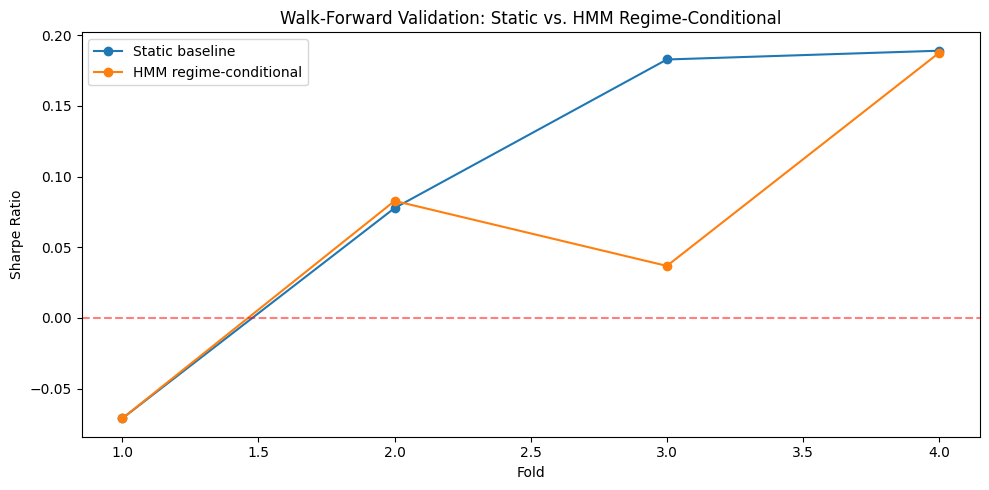

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(wf_df['fold'], wf_df['static_sharpe'], marker='o', label='Static baseline')
plt.plot(wf_df['fold'], wf_df['regime_sharpe'], marker='o', label='HMM regime-conditional')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Fold')
plt.ylabel('Sharpe Ratio')
plt.title('Walk-Forward Validation: Static vs. HMM Regime-Conditional')
plt.legend()
plt.tight_layout()
plt.show()

### 7.3 Comparison with Bayesian Optimization

| Method | Mean OOS Sharpe | Notes |
|---|:---:|---|
| Bayesian-optimized (`05`, walk-forward, 4 folds) | 0.157 | Joint 100-trial Optuna search per fold over gamma, kappa, alpha, beta, OFI threshold, window |
| Static baseline (this notebook, walk-forward, same fold sizes) | 0.0946 | Fixed `gamma=0.5`, `kappa=11.0` -- `04`'s univariate optimum |
| HMM regime-conditional (this notebook, walk-forward, same fold sizes) | 0.0591 | HMM refit per fold; `label_to_params` fixed, not optimized |

All three numbers come from different live trade windows (`05`'s run, and this notebook's two sections above), so this is a comparison of *methodologies*, not a controlled identical-data experiment.